# H08 固定训练划分下的日频/L2 对照

2026-10-07，本地研究事实。当前结论统一维护在 [研究卷宗](README.md#h08-fixed-split-comparison)。

本实验只比较相同分类器的 7 列日频与 39 列日频加 L2；使用相同资格、标签、日期、缺失填充值和日期等权。39 列模型来自 Job `907055ec-bd1b-48b4-8ba3-dcbb149e2531`，不重训。7 列模型由一次成功的隔离 HTTP POST → Job → CLI → workflow 生成。

[冻结方案](/home/wsw/app/research-evidence/subscription-fixed-split-2026-10-07-qu5v5rx2/protocol.json)在观察新日频模型结果前写入。完整代码、输入、API 记录、模型、失败现场及环境均在该证据目录；不读取可变共享输入进行比较。原始日历父对象漏复制造成一次拟合前失败，补齐同一父对象后按原请求重试，失败保留于 `failed-attempt-01/`。

本 Notebook 顺序复算输入、进行一次独立参考拟合、核对两模型保存预测、重算指标和生成图；不会再次提交 API Job。精确 API 恢复使用冻结 `run_api.py`、源码及输入，在另一个隔离根执行同一 `request.json`，不得覆盖原证据。

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import importlib.metadata
import json
import math
import sys

import joblib
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits

evidence = Path("/home/wsw/app/research-evidence/subscription-fixed-split-2026-10-07-qu5v5rx2")
storage = evidence / "storage"
sys.path.insert(0, str(evidence / "runtime-source"))
protocol = json.loads((evidence / "protocol.json").read_text())
assert hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest() == "41add61eb7eceb5a8f8d7dcfc423fd1a58cf1826c967c9b63d09d13ed70091ee"
run = json.loads((evidence / "api-artifacts.json").read_text())
daily_root = Path(run["root"]) / "training"
l2_root = evidence / "baseline-l2/training"
daily_schedule = json.loads((daily_root / "schedule.json").read_text())
l2_schedule = json.loads((l2_root / "schedule.json").read_text())
print("Daily Job:", json.loads((evidence / "http-status.json").read_text())["job"]["job_id"])
print("Protocol frozen:", protocol["frozen_at"])
print("Runtime baseline:", protocol["base_commit"])
print("scikit-learn:", importlib.metadata.version("scikit-learn"))

Daily Job: e3557768-ffbb-4f9b-8a45-3c707680c7df
Protocol frozen: 2026-10-07T23:06:03.205058+08:00
Runtime baseline: 76c25a279685b6961cda69143f542e8ec3936f51
scikit-learn: 1.8.0


## 1. 绑定冻结输入和代码

先核对源码、全部输入、原模型制品和本轮 API 制品的 SHA-256，再核对两模型的训练日期与参数。隔离服务使用无生产凭证的本地环境。

In [2]:
checks = Counter()
for manifest_name, root in (
    ("source-manifest.json", evidence / "runtime-source"),
    ("input-manifest.json", storage),
    ("baseline-manifest.json", evidence / "baseline-l2"),
):
    manifest = json.loads((evidence / manifest_name).read_text())
    for relative, expected in manifest.items():
        actual = root / relative
        assert actual.stat().st_size == expected["size_bytes"], relative
        assert hashlib.sha256(actual.read_bytes()).hexdigest() == expected["sha256"], relative
    checks[manifest_name] = len(manifest)
for relative, expected in run["artifacts"].items():
    assert hashlib.sha256((Path(run["root"]) / relative).read_bytes()).hexdigest() == expected["sha256"], relative
checks["daily_api_artifacts"] = len(run["artifacts"])
baseline_inputs = {row["path"]: row for row in json.loads((evidence / "baseline-input-manifest.json").read_text())}
current_inputs = json.loads((evidence / "input-manifest.json").read_text())
for relative, expected in current_inputs.items():
    if relative.startswith(("features/", "labels/")):
        assert baseline_inputs[relative]["sha256"] == expected["sha256"], relative
        assert baseline_inputs[relative]["size_bytes"] == expected["size_bytes"], relative
        checks["inputs_identical_to_original_baseline"] += 1
assert checks["inputs_identical_to_original_baseline"] == 912
versions = json.loads((evidence / "environment.json").read_text())["packages"]
for package in ("numpy", "pandas", "scikit-learn", "scipy", "joblib"):
    assert importlib.metadata.version(package) == versions[package], package
for field in ("train_dates", "purged_dates", "validation_dates", "eval_dates", "label_maturity_ts_us"):
    assert daily_schedule[field] == l2_schedule[field], field
for field in ("group", "model_params", "preprocessing", "sample_weight"):
    assert daily_schedule["configuration"][field] == l2_schedule["configuration"][field], field
daily_columns = daily_schedule["configuration"]["dataset"]["feature_columns"]
l2_columns = l2_schedule["configuration"]["dataset"]["feature_columns"]
assert len(daily_columns) == 7 and len(l2_columns) == 39
assert daily_columns == l2_columns[-7:]
assert daily_schedule["request"] == protocol["request"]
assert len(list(daily_root.glob("*.joblib"))) == 1
print(dict(checks))
print({field: len(daily_schedule[field]) for field in ("train_dates", "purged_dates", "validation_dates", "eval_dates")})

{'source-manifest.json': 169, 'input-manifest.json': 916, 'baseline-manifest.json': 52, 'daily_api_artifacts': 52, 'inputs_identical_to_original_baseline': 912}
{'train_dates': 106, 'purged_dates': 1, 'validation_dates': 27, 'eval_dates': 17}


## 2. 独立参考拟合

直接读取冻结 Parquet，通过完整样本键对齐；仅剔除未知训练标签。日权重为当日有效样本数倒数，再归一至全局均值 1。预处理固定填 0.5。参考拟合不调用训练 pipeline，用于检验实际 API 输出，并非新增候选或调参。

In [3]:
keys = ["symbol", "trade_date", "decision_ts_utc"]
train_parts = []
training_raw_rows = 0
training_missing_labels = 0
for day in daily_schedule["train_dates"]:
    features = pd.read_parquet(storage / f"features/previous_day_daily_l2/v1/trade_date={day}/data.parquet").set_index(keys)
    labels = pd.read_parquet(storage / f"labels/next_day_high_top_decile/v1/trade_date={day}/data.parquet").set_index(keys)
    assert features.index.is_unique and features.index.equals(labels.index)
    valid = labels.y_event.notna()
    frame = features.loc[valid, daily_columns].copy()
    frame["target"] = labels.loc[valid, "y_event"]
    frame["weight"] = 1.0 / int(valid.sum())
    train_parts.append(frame)
    training_raw_rows += len(features)
    training_missing_labels += int((~valid).sum())
training = pd.concat(train_parts)
assert len(training) == 527875 and training_missing_labels == 410
weights = training.weight.to_numpy(dtype=float)
weights = weights / weights.mean()
reference = HistGradientBoostingClassifier(**daily_schedule["configuration"]["model_params"])
with threadpool_limits(limits=1):
    reference.fit(training[daily_columns].fillna(0.5).to_numpy(dtype=float),
                  training.target.to_numpy(dtype=float), sample_weight=weights)
joblib.dump(reference, evidence / "reference-daily-model.joblib")
daily_model = joblib.load(daily_root / "model.joblib")
l2_model = joblib.load(l2_root / "model.joblib")
assert reference.n_iter_ == daily_model.model.n_iter_ == 100
print({"raw_rows": training_raw_rows, "missing_labels": training_missing_labels, "fit_rows": len(training),
       "features": len(daily_columns), "iterations": reference.n_iter_})

{'raw_rows': 528285, 'missing_labels': 410, 'fit_rows': 527875, 'features': 7, 'iterations': 100}


## 3. 核对44日预测、名单与评价

先根据预测冻结 Top50，随后连接未来标签计算有效分母，不补选。核对日频模型与独立参考拟合的219,985个预测逐值一致，并用两个保存模型重放。五种规则应在两次运行间完全相同。

Precision、Recall、F1、Lift、覆盖率及新计算的 AUC/Brier 都先按日计算。以下表中的均值按日期等权，不将股票日视为独立时间样本。

In [4]:
rules = {
    "rule_amount": "baseline_amount",
    "rule_momentum": "baseline_momentum",
    "rule_reversal": "baseline_reversal",
    "rule_volatility": "lag_f_d_close_volatility_60d_asof_tminus1_rank",
    "rule_turnover": "lag_f_d_turnover_rate_mean_20d_asof_tminus1_rank",
}
saved_daily = pd.read_parquet(daily_root / "selection-metrics.parquet").set_index(["stage", "trade_date", "method"])
saved_l2 = pd.read_parquet(l2_root / "selection-metrics.parquet").set_index(["stage", "trade_date", "method"])
lists_daily = pd.read_parquet(daily_root / "selections.parquet").set_index(["stage", "trade_date", "method"])
lists_l2 = pd.read_parquet(l2_root / "selections.parquet").set_index(["stage", "trade_date", "method"])
pd.testing.assert_frame_equal(
    saved_daily.loc[saved_daily.index.get_level_values("method") != "model"],
    saved_l2.loc[saved_l2.index.get_level_values("method") != "model"],
)
metrics_rows = []
diagnostic_rows = []
for stage, dates, metrics_file in (
    ("validation", daily_schedule["validation_dates"], "validation-metrics.json"),
    ("evaluation", daily_schedule["eval_dates"], "metrics.json"),
):
    ic_records = {}
    for method, model_root in (("daily7", daily_root), ("all39", l2_root)):
        observations = json.loads((model_root / metrics_file).read_text())["observations"]
        ic_records[method] = {Path(row["prediction_ref"]).stem: row for row in observations}
    for day in dates:
        features = pd.read_parquet(storage / f"features/previous_day_daily_l2/v1/trade_date={day}/data.parquet").set_index(keys)
        event_file = storage / f"labels/next_day_high_top_decile/v1/trade_date={day}/data.parquet"
        events = pd.read_parquet(event_file).set_index(keys)
        ranks = pd.read_parquet(storage / f"labels/next_day_high_return_rank/v1/trade_date={day}/data.parquet").set_index(keys)
        pred_daily = pd.read_parquet(daily_root / f"predictions/{day}.parquet").set_index(keys)
        pred_l2 = pd.read_parquet(l2_root / f"predictions/{day}.parquet").set_index(keys)
        for frame in (features, events, ranks, pred_daily, pred_l2):
            assert frame.index.is_unique and frame.index.equals(features.index)
        with threadpool_limits(limits=1):
            expected = reference.predict_proba(features[daily_columns].fillna(0.5).to_numpy(dtype=float))[:, 1]
        np.testing.assert_array_equal(expected, pred_daily.prediction.to_numpy())
        np.testing.assert_array_equal(daily_model.predict(features[daily_columns].to_numpy(dtype=float)), expected)
        np.testing.assert_array_equal(l2_model.predict(features[l2_columns].to_numpy(dtype=float)), pred_l2.prediction.to_numpy())
        checks["paired_prediction_rows"] += len(features)
        scores = {"daily7": pred_daily.prediction.to_numpy(), "all39": pred_l2.prediction.to_numpy()}
        scores.update({name: features[column].to_numpy() for name, column in rules.items()})
        y_rank = ranks.y_rank_return.to_numpy(dtype=float)
        y_event = events.y_event.to_numpy(dtype=float)
        known = np.isfinite(y_rank)
        np.testing.assert_array_equal(known, np.isfinite(y_event))
        np.testing.assert_array_equal(y_event[known], (y_rank[known] > 0.9).astype(float))
        for method, score in scores.items():
            order = pd.DataFrame({"symbol": features.index.get_level_values("symbol"), "score": score})
            selected = order.sort_values(["score", "symbol"], ascending=[False, True], na_position="last").head(50)
            positions = selected.index.to_numpy()
            saved_method = "model" if method in ("daily7", "all39") else method
            saved_metrics = saved_daily if method == "daily7" else saved_l2
            saved_lists = lists_daily if method == "daily7" else lists_l2
            saved_row = saved_metrics.loc[(stage, day, saved_method)]
            assert selected.symbol.tolist() == list(saved_lists.loc[(stage, day, saved_method), "symbols"])
            n = int(known.sum())
            selected_known = int(known[positions].sum())
            hits = int((y_rank[positions] > 0.9).sum())
            positives = int((y_rank > 0.9).sum())
            precision = hits / selected_known
            recall = hits / positives
            baseline = positives / n
            computed = {
                "pool_size": len(features), "pool_known": n, "selected": len(selected),
                "selected_known": selected_known, "hits": hits, "opportunities": positives,
                "unknown_selected": len(selected) - selected_known,
                "unknown_unselected": len(features) - n - (len(selected) - selected_known),
                "pool_coverage": n / len(features), "selection_coverage": selected_known / len(selected),
                "precision": precision, "recall": recall, "f1": 2 * hits / (selected_known + positives),
                "random_precision": baseline, "lift": precision / baseline,
                "precision_lower": hits / len(selected),
                "precision_upper": (hits + len(selected) - selected_known) / len(selected),
            }
            for field, value in computed.items():
                assert value == saved_row[field], (stage, day, method, field)
            metrics_rows.append({"stage": stage, "trade_date": day, "method": method, **computed})
            checks["recomputed_method_days"] += 1
            if method in ("daily7", "all39"):
                record = ic_records[method][day]
                assert hashlib.sha256(event_file.read_bytes()).hexdigest() == record["label_sha256"]
                ic = float(spearmanr(score[known], y_event[known]).statistic)
                assert abs(ic - record["value"]) < 1e-13
                diagnostic_rows.append({
                    "stage": stage, "trade_date": day, "method": method,
                    "ic": ic, "auc": float(roc_auc_score(y_event[known], score[known])),
                    "brier": float(brier_score_loss(y_event[known], score[known])),
                    "selected_mean_probability": float(score[positions][known[positions]].mean()),
                })
                checks["ic_days"] += 1
metrics = pd.DataFrame(metrics_rows)
diagnostics = pd.DataFrame(diagnostic_rows)
summary = metrics.groupby(["stage", "method"], sort=False).agg(
    days=("trade_date", "size"), precision=("precision", "mean"), hits=("hits", "sum"),
    selected_known=("selected_known", "sum"), unknown_selected=("unknown_selected", "sum"),
    recall=("recall", "mean"), f1=("f1", "mean"), lift=("lift", "mean"),
    pool_coverage=("pool_coverage", "mean"), selection_coverage=("selection_coverage", "mean"),
).reset_index()
summary.to_csv(evidence / "comparison-summary.csv", index=False)
metrics.to_parquet(evidence / "comparison-daily.parquet", index=False)
diagnostics.to_csv(evidence / "probability-diagnostics.csv", index=False)
print(summary.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
print("Verification:", dict(checks))

     stage          method  days  precision  hits  selected_known  unknown_selected   recall       f1     lift  pool_coverage  selection_coverage
validation          daily7    27   0.320484   432            1348                 2 0.032279 0.058648 3.228068       0.999622            0.998519
validation           all39    27   0.331247   446            1346                 4 0.033288 0.060494 3.332821       0.999622            0.997037
validation     rule_amount    27   0.210370   284            1350                 0 0.021025 0.038227 2.099081       0.999622            1.000000
validation   rule_momentum    27   0.272683   367            1346                 4 0.027446 0.049869 2.749257       0.999622            0.997037
validation   rule_reversal    27   0.257037   347            1350                 0 0.025740 0.046791 2.569188       0.999622            1.000000
validation rule_volatility    27   0.360000   486            1350                 0 0.036015 0.065475 3.595600       0.99962

## 4. 配对差值与预先固定的不确定性计算

差值统一为 **39列减7列**。按完整交易日做配对，采用5日循环区块、20,000次 bootstrap、seed=20261007，两个区间分别计算。保留双侧95%名义区间和单侧95%下界。

预先固定的探索性关注判据为：两段均值差各至少 +2 个百分点，且各自单侧95%下界大于0。它不是H07旧判据的迁移，也不触发采用。全部日期已经被研究消费，区间仅用于诊断，不能充当新的确认性显著性结果。

In [5]:
bootstrap = protocol["uncertainty"]
paired = metrics.loc[metrics.method.isin(["daily7", "all39"])].pivot(
    index=["stage", "trade_date"], columns="method", values="precision"
)
paired["difference"] = paired.all39 - paired.daily7
comparison_rows = []
for stage in ("validation", "evaluation"):
    values = paired.xs(stage).difference.to_numpy()
    random = np.random.default_rng(bootstrap["seed"])
    blocks = math.ceil(len(values) / bootstrap["block_sessions"])
    starts = random.integers(0, len(values), size=(bootstrap["resamples"], blocks))
    positions = (starts[..., None] + np.arange(bootstrap["block_sessions"])) % len(values)
    positions = positions.reshape(bootstrap["resamples"], -1)[:, :len(values)]
    samples = values[positions].mean(axis=1)
    low, high = np.quantile(samples, [0.025, 0.975])
    lower_one_sided = float(np.quantile(samples, 0.05))
    comparison_rows.append({
        "stage": stage, "days": len(values), "mean_difference": float(values.mean()),
        "ci95_lower": float(low), "ci95_upper": float(high), "one_sided95_lower": lower_one_sided,
        "wins": int((values > 0).sum()), "ties": int((values == 0).sum()), "losses": int((values < 0).sum()),
        "exploratory_criterion_met": bool(values.mean() >= 0.02 and lower_one_sided > 0),
    })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(evidence / "paired-comparison.csv", index=False)
paired.to_csv(evidence / "paired-daily.csv")
print(comparison.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
print(diagnostics.groupby(["stage", "method"], sort=False)[["ic", "auc", "brier", "selected_mean_probability"]].mean().to_string())

     stage  days  mean_difference  ci95_lower  ci95_upper  one_sided95_lower  wins  ties  losses  exploratory_criterion_met
validation    27         0.010763   -0.001421    0.024611           0.000227    12     5      10                      False
evaluation    17         0.022929    0.012941    0.034118           0.014166     9     3       5                       True
                         ic       auc     brier  selected_mean_probability
stage      method                                                         
validation daily7  0.220314  0.712240  0.084462                   0.329168
           all39   0.227113  0.718750  0.083949                   0.340740
evaluation daily7  0.226693  0.718650  0.083986                   0.344569
           all39   0.232807  0.724512  0.083571                   0.355378


## 5. 同口径比较图

左图比较两模型与固定高波动率规则的日均命中率；右图展示39列减7列的逐日差值。虚线 +2pp 为本轮事前固定的实际改善尺度，不是未来最低收益保证。两段历史已消费。

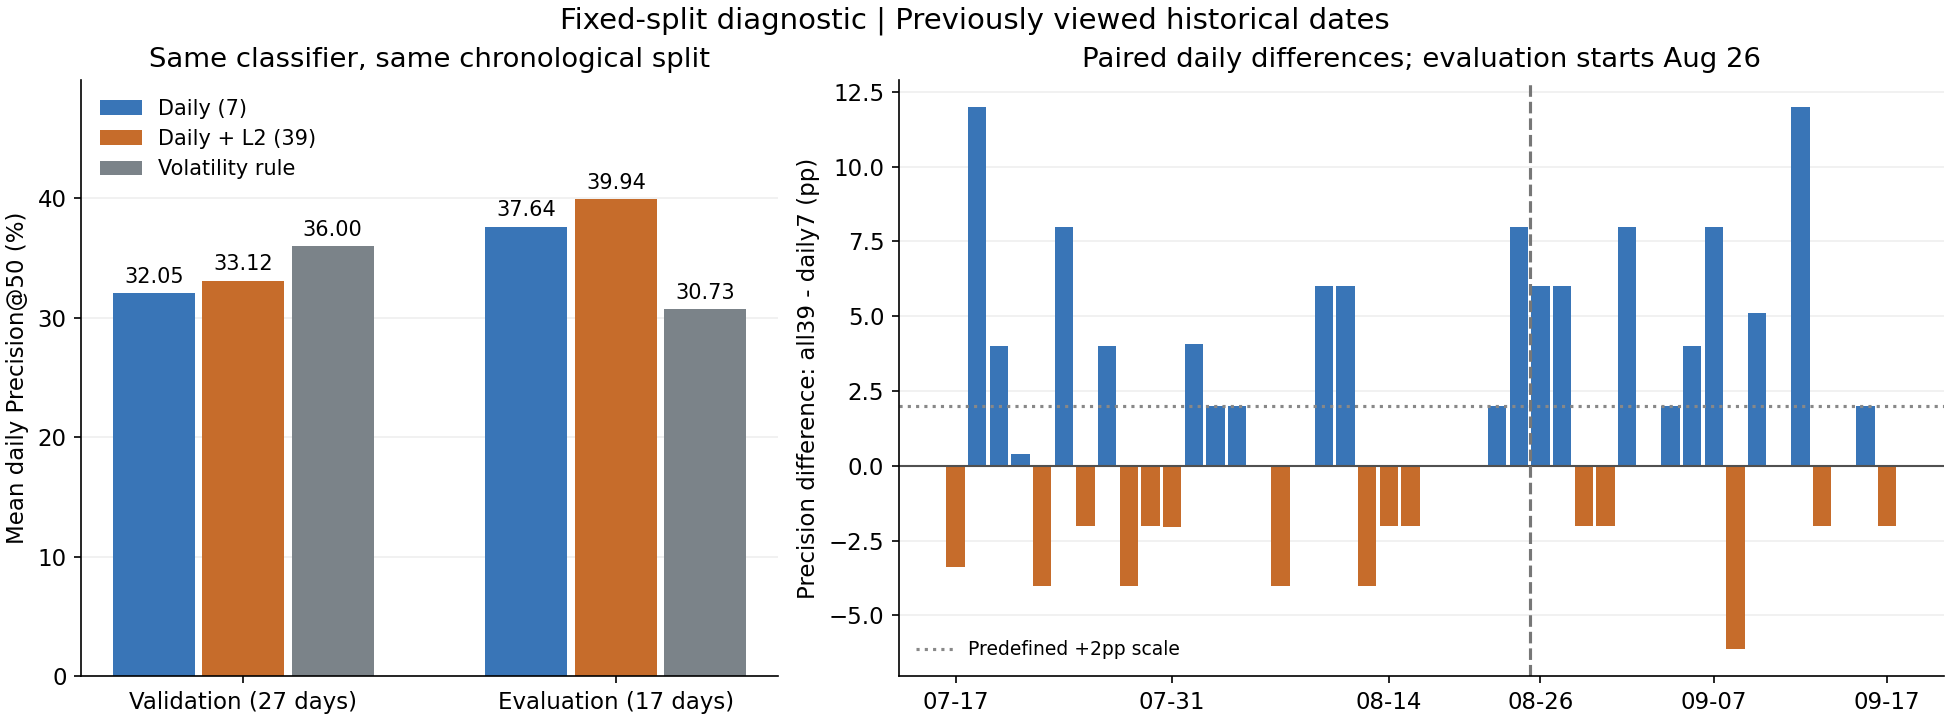

In [6]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.5]}, layout="constrained")
colors = {"daily7": "#3975B7", "all39": "#C66C2B", "rule_volatility": "#7B8389"}
labels = {"daily7": "Daily (7)", "all39": "Daily + L2 (39)", "rule_volatility": "Volatility rule"}
stages = ["validation", "evaluation"]
for index, method in enumerate(colors):
    values = [float(summary.loc[(summary.stage == stage) & (summary.method == method), "precision"].iloc[0]) * 100 for stage in stages]
    bars = axes[0].bar(np.arange(2) + (index - 1) * 0.24, values, width=0.22, label=labels[method], color=colors[method])
    axes[0].bar_label(bars, fmt="%.2f", padding=3, fontsize=10)
axes[0].set_xticks([0, 1], ["Validation (27 days)", "Evaluation (17 days)"])
axes[0].set_ylabel("Mean daily Precision@50 (%)")
axes[0].set_ylim(0, max(summary.precision) * 100 + 10)
axes[0].legend(frameon=False, loc="upper left", fontsize=10)
axes[0].set_title("Same classifier, same chronological split")
ordered = pd.concat([paired.xs(stage) for stage in stages])
x = np.arange(len(ordered))
axes[1].bar(x, ordered.difference.to_numpy() * 100, color=np.where(ordered.difference >= 0, "#3975B7", "#C66C2B"), width=0.85)
axes[1].axhline(0, color="#505050", linewidth=1)
axes[1].axhline(2, color="#888888", linestyle=":", label="Predefined +2pp scale")
axes[1].axvline(26.5, color="#777777", linestyle="--")
ticks = [0, 10, 20, 27, 35, 43]
axes[1].set_xticks(ticks, [str(ordered.index[i])[5:] for i in ticks])
axes[1].set_ylabel("Precision difference: all39 - daily7 (pp)")
axes[1].set_title("Paired daily differences; evaluation starts Aug 26")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle("Fixed-split diagnostic | Previously viewed historical dates", fontsize=14)
figure_path = evidence / "fixed-split-comparison.png"
fig.savefig(figure_path, dpi=150)
plt.close(fig)
display(Image(filename=str(figure_path)))

## 6. 新日期确认的冻结范围与尚缺条件

本轮结果出炉前，方案已固定为2026-10-08起的60个正式交易日（当前冻结日历至2026-12-30）。两模型保持冻结，不根据此次历史比较改变候选；唯一主要比较为39列减7列的日均 Precision@50，最低实际改善为2个百分点，单侧95%下界须大于0。两模型各自入选标签覆盖须≥98%，完整60日决策记录不可删日或补日。

这里只登记研究方案，尚未启动采集或调度。前向观察必须保存决策前实际接收时间、原始版本/哈希、资格快照、模型就绪时间及版本、完整候选和Top50。当前输入只到09-17，历史22:00假设不能冒充实际接收事实；如果错过首日采集，保留失败，重新冻结未来窗口，不把事后补算升级为严格确认。

原09:00盘前模型不直接接入现有15:00日频回测入口。实际收益回放仍需明确退出、费用、未成交与持仓等语义；不使用次日最高价冒充可执行卖出。

In [7]:
verification = {
    "job_id": json.loads((evidence / "http-status.json").read_text())["job"]["job_id"],
    "protocol_sha256": hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest(),
    "source_commit": protocol["base_commit"],
    "checks": dict(checks),
    "training_rows": len(training),
    "training_missing_labels": training_missing_labels,
    "daily_feature_columns": daily_columns,
    "independent_reference_predictions_exact": True,
    "both_saved_models_replayed_exactly": True,
    "all_rules_identical_between_runs": True,
    "summary": summary.to_dict(orient="records"),
    "paired_comparison": comparison.to_dict(orient="records"),
    "exploratory_signal_criterion_met_both_periods": bool(comparison.exploratory_criterion_met.all()),
    "new_independent_dates_evaluated": 0,
    "actual_reception_or_trading_verified": False,
    "future_protocol_started": False,
    "technical_failures": ["failed-attempt-01/reason.json", "failed-analysis-01/reason.json", "failed-analysis-02/reason.json"],
}
(evidence / "comparison-verification.json").write_text(json.dumps(verification, ensure_ascii=False, indent=2))
print("Validated:", verification["checks"])
print("Exploratory criterion met in both periods:", verification["exploratory_signal_criterion_met_both_periods"])
print("New independent dates:", verification["new_independent_dates_evaluated"])

Validated: {'source-manifest.json': 169, 'input-manifest.json': 916, 'baseline-manifest.json': 52, 'daily_api_artifacts': 52, 'inputs_identical_to_original_baseline': 912, 'paired_prediction_rows': 219985, 'recomputed_method_days': 308, 'ic_days': 88}
Exploratory criterion met in both periods: False
New independent dates: 0
